In [1]:
import numpy as np
from scipy import linalg
from scipy.ndimage import gaussian_filter
from sklearn.utils import check_random_state


def generate_one_subject_data(latent, w, rng, size=12, smooth=1.0, snr=20):
    """Generate data for one subject given latent variables weights."""
    n_samples = latent.shape[0]

    X = latent @ w
    X = gaussian_filter(
        X.reshape(n_samples, size, size), sigma=(0, smooth, smooth)
    ).reshape(n_samples, -1)

    noise = gaussian_filter(
        rng.randn(n_samples, size, size), sigma=(0, smooth, smooth)
    ).reshape(n_samples, -1)

    scale = (
        linalg.norm(X, ord="fro")
        / (10 ** (snr / 20))
        / linalg.norm(noise, ord="fro")
    )
    X += scale * noise
    X -= X.mean(axis=0)

    return X


def simulate_paired_subjects(
    snr=20,
    n_samples_alignment=100,
    n_samples_train=100,
    n_samples_test=100,
    size=12,
    smooth=1.0,
    random_state=None,
):
    """Simulate two subjects with a shared latent signal."""
    rng = check_random_state(random_state)
    n_samples = n_samples_alignment + n_samples_train + n_samples_test

    # Source subject patterns
    w1_source, w2_source = np.zeros((size, size)), np.zeros((size, size))
    w1_source[0, -1] = 1
    w2_source[-1, 2] = -1
    w_source = np.stack([w1_source, w2_source])
    w_source = gaussian_filter(w_source, sigma=smooth)
    w_source = w_source.reshape(2, -1)
    coefs_source = w_source.sum(axis=0).reshape(size, size)

    # Target subject patterns
    w1_target, w2_target = np.zeros((size, size)), np.zeros((size, size))
    w1_target[0, -1] = 0.25
    w1_target[1, -size // 2] = 0.75
    w2_target[-1, size // 4] = -1
    w_target = np.stack([w1_target, w2_target])
    w_target = gaussian_filter(w_target, sigma=smooth)
    w_target = w_target.reshape(2, -1)
    coefs_target = w_target.sum(axis=0).reshape(size, size)

    # Simulate latent variables and generate synthetic signals
    latent = rng.randn(n_samples, 2)
    X_source = generate_one_subject_data(
        latent, w_source, rng, size=size, smooth=smooth, snr=snr
    )
    X_target = generate_one_subject_data(
        latent, w_target, rng, size=size, smooth=smooth, snr=snr
    )

    y = np.sign(latent[:, 0])
    train_end = n_samples_train
    test_end = n_samples_train + n_samples_test

    return (
        X_source[-n_samples_alignment:],
        X_source[:train_end],
        X_source[train_end:test_end],
        coefs_source,
        X_target[-n_samples_alignment:],
        X_target[:train_end],
        X_target[train_end:test_end],
        coefs_target,
        y[:train_end],
        y[train_end:test_end],
    )

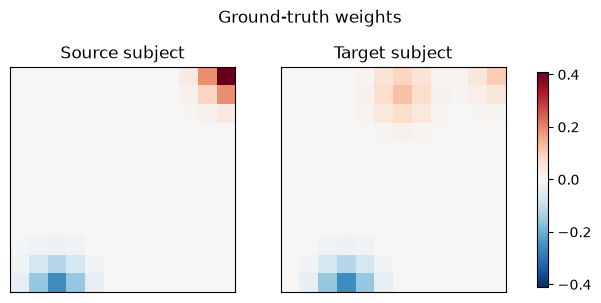

In [2]:
import matplotlib.pyplot as plt

size = 12
(
    X_alignment_source,
    X_train_source,
    X_test_source,
    coefs_source,
    X_alignment_target,
    X_train_target,
    X_test_target,
    coefs_target,
    y_train,
    y_test,
) = simulate_paired_subjects(
    snr=20, n_samples_alignment=100, size=size, random_state=0
)


def plot_patterns(patterns, titles, suptitle):
    fig, axes = plt.subplots(
        1, len(patterns), figsize=(4 * len(patterns), 3.5)
    )
    axes = np.atleast_1d(axes)
    vmax = np.abs(patterns).max()
    for ax, pattern, title in zip(axes, patterns, titles, strict=True):
        im = ax.imshow(pattern, vmin=-vmax, vmax=vmax, cmap="RdBu_r")
        ax.set_title(title)
        ax.set_xticks(())
        ax.set_yticks(())
    fig.colorbar(im, ax=axes, shrink=0.8)
    fig.suptitle(suptitle)


plot_patterns(
    [coefs_source, coefs_target],
    ["Source subject", "Target subject"],
    "Ground-truth weights",
)

Naive SVM score on source: 0.77
Naive SVM score on target: 0.25


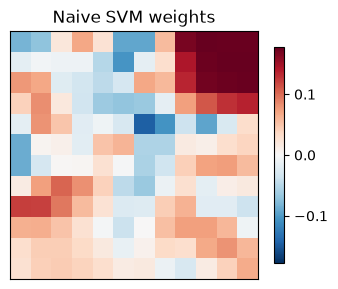

In [3]:
from sklearn import svm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_naive = make_pipeline(StandardScaler(), svm.SVC(kernel="linear"))
svm_naive.fit(X_train_source, y_train)
print(
    "Naive SVM score on source:",
    svm_naive.score(X_test_source, y_test),
)
print(
    "Naive SVM score on target:",
    svm_naive.score(X_test_target, y_test),
)

plot_patterns(
    [svm_naive.named_steps["svc"].coef_.reshape(size, size)],
    ["Naive SVM weights"],
    "",
)

SVM aligned with procrustes target score: 0.84


SVM aligned with ot target score: 0.89
SVM aligned with ridge target score: 0.54


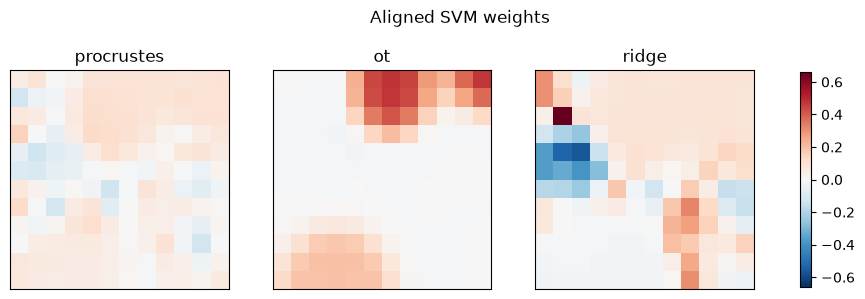

In [4]:
from fmralign import PairwiseAlignment

methods = ["procrustes", "ot", "ridge"]
aligned_weights = []

for method in methods:
    algo = PairwiseAlignment(method=method)
    algo.fit(X_alignment_source, X_alignment_target)
    X_train_source_aligned = algo.transform(X_train_source)

    svm_aligned = make_pipeline(StandardScaler(), svm.SVC(kernel="linear"))
    svm_aligned.fit(X_train_source_aligned, y_train)
    aligned_weights.append(
        svm_aligned.named_steps["svc"].coef_.reshape(size, size)
    )

    print(
        f"SVM aligned with {method} target score:",
        svm_aligned.score(X_test_target, y_test),
    )

plot_patterns(aligned_weights, methods, "Aligned SVM weights")

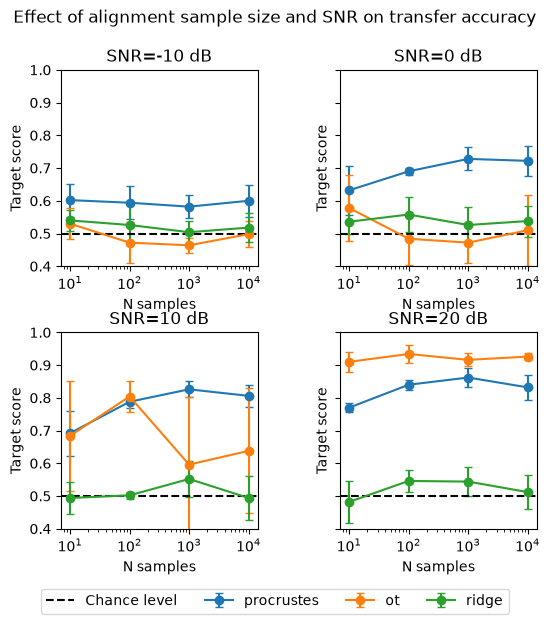

In [5]:
def score_method(method, snr, n_samples_alignment, random_state):
    (
        X_alignment_source,
        X_train_source,
        _,
        _,
        X_alignment_target,
        _,
        X_test_target,
        _,
        y_train,
        y_test,
    ) = simulate_paired_subjects(
        snr=snr,
        size=12,
        n_samples_alignment=n_samples_alignment,
        random_state=random_state,
    )

    algo = PairwiseAlignment(method=method)
    algo.fit(X_alignment_source, X_alignment_target)
    X_train_source_aligned = algo.transform(X_train_source)

    svm_aligned = make_pipeline(StandardScaler(), svm.SVC(kernel="linear"))
    svm_aligned.fit(X_train_source_aligned, y_train)
    return svm_aligned.score(X_test_target, y_test)


n_samples = [10, 100, 1000, 10000]
snrs = [-10, 0, 10, 20]
n_repeats = 5

fig, axes = plt.subplots(2, 2, figsize=(6, 6.5), sharey=True)

for ax, snr in zip(axes.ravel(), snrs, strict=True):
    for method in methods:
        scores = np.array(
            [
                [
                    score_method(method, snr, n, random_state)
                    for random_state in range(n_repeats)
                ]
                for n in n_samples
            ]
        )
        ax.errorbar(
            n_samples,
            scores.mean(axis=1),
            yerr=scores.std(axis=1),
            marker="o",
            capsize=3,
            label=method,
        )
    ax.axhline(0.5, color="k", linestyle="--", label="Chance level")
    ax.set_xscale("log")
    ax.set_xlabel("N samples")
    ax.set_ylabel("Target score")
    ax.set_title(f"SNR={snr} dB")
    ax.set_ylim(0.4, 1)
    ax.set_box_aspect(1)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=len(labels),
)
fig.suptitle("Effect of alignment sample size and SNR on transfer accuracy")
fig.tight_layout(rect=(0, 0.1, 1, 0.98))